In [1]:

# Install scikit-learn if required
%pip install scikit-learn


Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
Note: you may need to restart the kernel to use updated packages.


In [1]:

# Import machine learning libraries

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

print("Machine learning libraries imported successfully!")


Machine learning libraries imported successfully!


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [8]:
df = pd.read_csv("Jan_Samadhan_Cleaned_Data.csv")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (500, 8)


,Complaint_ID,State,Department,Complaint_Date,Status,Resolution_Days,Complaint_Description,Cleaned_Complaint
0,JS0001,Madhya Pradesh,Electricity,2025-05-06,Pending,9.0,Frequent power cuts in our village,frequent power cuts in our village
1,JS0002,Uttar Pradesh,Electricity,2025-10-30,Resolved,3.0,Electricity connection request is pending,electricity connection request is pending
2,JS0003,Bihar,Electricity,2025-04-30,In Progress,39.0,Frequent power cuts in our village,frequent power cuts in our village
3,JS0004,Bihar,Electricity,2025-11-29,In Progress,35.0,Electricity connection request is pending,electricity connection request is pending
4,JS0005,Rajasthan,Health,2025-10-29,Resolved,52.0,Doctor is not available at the health centre,doctor is not available at the health centre


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Use complete dataset
X = df["Complaint_Description"].fillna("")
y = df["Department"]

# Convert text into numerical features
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=1000,
    ngram_range=(1, 2)
)

X_tfidf = vectorizer.fit_transform(X)

# Train model using all rows
model = LogisticRegression(max_iter=1000, random_state=42)

model.fit(X_tfidf, y)

print("Model trained on:", len(df), "records")

Model trained on: 500 records


In [11]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_tfidf)

print("Training Accuracy:", accuracy_score(y, y_pred))

print(classification_report(y, y_pred))

Training Accuracy: 0.998
              precision    recall  f1-score   support

   Education       1.00      1.00      1.00       103
 Electricity       0.99      1.00      0.99        95
      Health       1.00      1.00      1.00       106
       Other       0.00      0.00      0.00         1
Public Works       1.00      1.00      1.00       103
Water Supply       1.00      1.00      1.00        92

    accuracy                           1.00       500
   macro avg       0.83      0.83      0.83       500
weighted avg       1.00      1.00      1.00       500



/opt/conda/envs/anaconda-ai-2025.12-py312/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/envs/anaconda-ai-2025.12-py312/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/envs/anaconda-ai-2025.12-py312/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, 

In [13]:
complaint = [
    "Electricity bill is incorrect"
]

complaint_tfidf = vectorizer.transform(complaint)

prediction = model.predict(complaint_tfidf)

print("Predicted Department:", prediction[0])

Predicted Department: Electricity


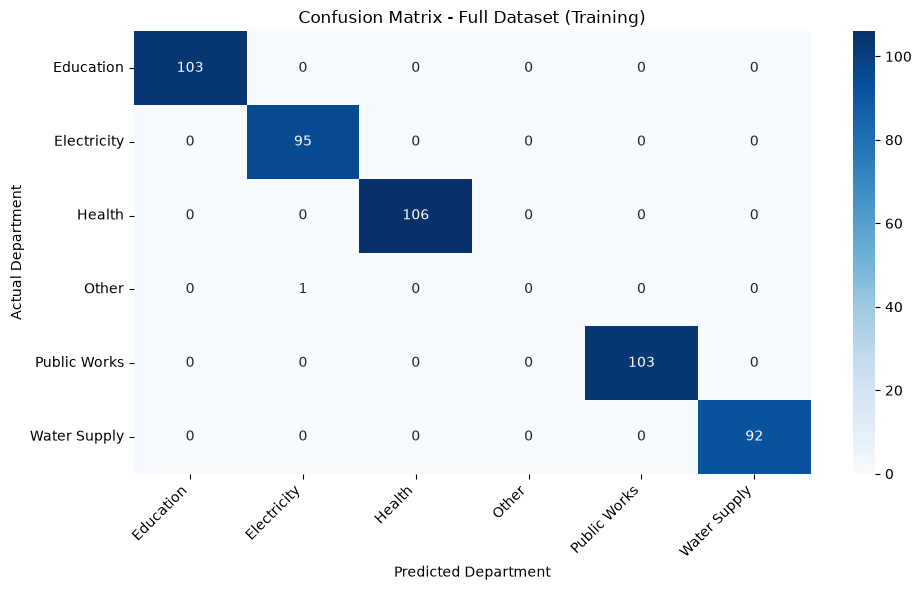

In [14]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y, y_pred, labels=model.classes_)

plt.figure(figsize=(10, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Department")
plt.ylabel("Actual Department")
plt.title("Confusion Matrix - Full Dataset (Training)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [15]:
import joblib

joblib.dump(model, "jan_samadhan_model.pkl")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

['tfidf_vectorizer.pkl']

In [ ]:
Task 2.3 – Logistic Regression vs. Deep Neural Networks
We selected Logistic Regression because it is lightweight, computationally efficient and suitable for 
text classification tasks with relatively small datasets. It requires less training time, memory and
processing power compared to Deep Neural Networks such as BERT. Logistic Regression combined
